In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from xgboost import XGBClassifier
from sklearn.metrics import roc_auc_score, accuracy_score, precision_score
from scipy.stats import spearmanr

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
RAW = ROOT / 'data' / 'raw'

df = pd.read_parquet(RAW / 'EURUSD_M5_features.parquet')
df = df.sort_values('time').reset_index(drop=True)

# Lista de features = todas menos as colunas administrativas
COLS_ADMIN = ['time','open','high','low','close','tick_volume','target','target_bin']
FEATURES = [c for c in df.columns if c not in COLS_ADMIN]

print(f"Shape: {df.shape}")
print(f"Features: {len(FEATURES)}")
print(f"Período: {df['time'].min()} → {df['time'].max()}")

Shape: (9951, 63)
Features: 55
Período: 2026-08-10 10:45:00 → 2026-09-25 23:55:00


In [2]:
CORTE_IDX = int(len(df) * 0.85)
CORTE_TIME = df['time'].iloc[CORTE_IDX]

treino = df.iloc[:CORTE_IDX].copy()
teste  = df.iloc[CORTE_IDX:].copy()

print(f"Treino: {len(treino)}  ({treino['time'].min()} → {treino['time'].max()})")
print(f"Teste:  {len(teste)}   ({teste['time'].min()} → {teste['time'].max()})")
print(f"Target treino: {treino['target_bin'].mean():.4f}")
print(f"Target teste:  {teste['target_bin'].mean():.4f}")

Treino: 8458  (2026-08-10 10:45:00 → 2026-09-18 19:30:00)
Teste:  1493   (2026-09-18 19:35:00 → 2026-09-25 23:55:00)
Target treino: 0.4805
Target teste:  0.4488


In [3]:
X_tr = treino[FEATURES]
y_tr = treino['target_bin']
X_te = teste[FEATURES]
y_te = teste['target_bin']

model = XGBClassifier(
    n_estimators=300,
    max_depth=3,
    learning_rate=0.03,
    subsample=0.8,
    colsample_bytree=0.8,
    min_child_weight=50,
    reg_alpha=0.5,
    reg_lambda=2.0,
    objective='binary:logistic',
    eval_metric='auc',
    tree_method='hist',
    random_state=42,
    n_jobs=-1,
)

model.fit(X_tr, y_tr, verbose=False)

# Probabilidades e previsões
prob_te = model.predict_proba(X_te)[:, 1]

# Métricas
auc = roc_auc_score(y_te, prob_te)
acc = accuracy_score(y_te, (prob_te > 0.5).astype(int))
prec = precision_score(y_te, (prob_te > 0.5).astype(int), zero_division=0)
ic, pval = spearmanr(prob_te, teste['target'].values)

print(f"=== RESULTADO M5 EURUSD ===")
print(f"AUC:      {auc:.4f}")
print(f"Acurácia: {acc:.4f}")
print(f"Precision:{prec:.4f}")
print(f"IC:       {ic:.4f}  p={pval:.4f}")
print(f"\nBaseline (chutar 0): {max(y_te.mean(), 1-y_te.mean()):.4f}")

=== RESULTADO M5 EURUSD ===
AUC:      0.5035
Acurácia: 0.5010
Precision:0.4394
IC:       nan  p=nan

Baseline (chutar 0): 0.5512


In [4]:
# Estatísticas do target em pips
PIP = 0.0001
target_pips = teste['target'] / PIP

print(f"Target em pips (M5):")
print(f"  Mediana: {target_pips.median():.2f} pips")
print(f"  Média:   {target_pips.mean():.2f} pips")
print(f"  Std:     {target_pips.std():.2f} pips")

# Custo estimado
SPREAD_PIPS = 1.0        # assuma 1 pip de custo round-trip
CUSTO_PCT = SPREAD_PIPS * PIP

print(f"\nCusto por trade (assumido): {SPREAD_PIPS} pips = {CUSTO_PCT*100:.4f}%")
print(f"Target mediano / Custo = {target_pips.median() / SPREAD_PIPS:.2f}")

Target em pips (M5):
  Mediana: -0.09 pips
  Média:   -0.05 pips
  Std:     1.76 pips

Custo por trade (assumido): 1.0 pips = 0.0100%
Target mediano / Custo = -0.09


=== BACKTEST LONG-ONLY M5 ===
Sinais no teste: 218 de 1493 (14.6%)
PnL total: -2.3622%
PnL médio por dia: -0.3937%
Dias positivos: 0 / 6


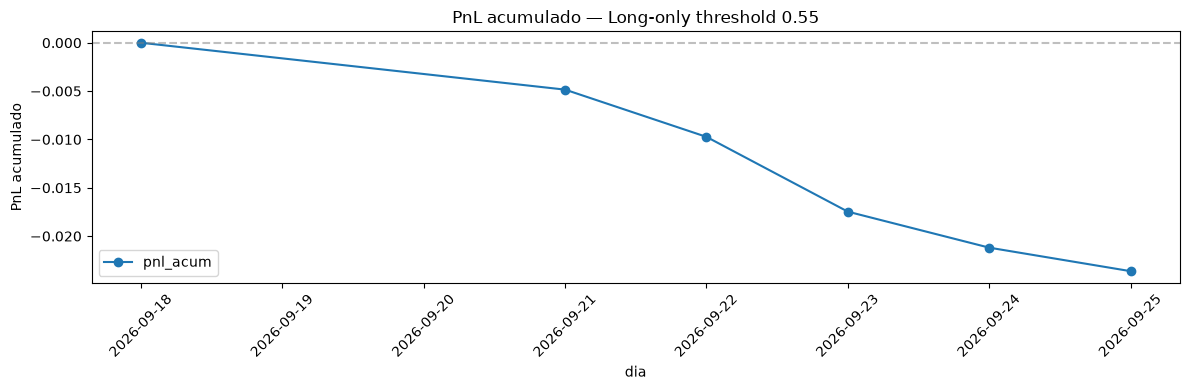

In [5]:
# Configuração
SPREAD_PIPS = 1.0
CUSTO_PCT = SPREAD_PIPS * 0.0001  # 0,01% por trade

# Sinal: só opera quando o modelo tem confiança
THRESHOLD = 0.55   # prob > 55% → long

teste_bt = teste.copy()
teste_bt['prob'] = prob_te
teste_bt['sinal'] = (teste_bt['prob'] > THRESHOLD).astype(int)

# P&L por trade = target - custo (se entrou)
teste_bt['pnl'] = teste_bt['sinal'] * (teste_bt['target'] - CUSTO_PCT)

# Agrega por dia
teste_bt['dia'] = teste_bt['time'].dt.date
pnl_diario = teste_bt.groupby('dia').agg(
    n_trades=('sinal', 'sum'),
    pnl_total=('pnl', 'sum'),
    target_medio=('target', 'mean'),
).reset_index()

pnl_diario['pnl_acum'] = pnl_diario['pnl_total'].cumsum()

print(f"=== BACKTEST LONG-ONLY M5 ===")
print(f"Sinais no teste: {teste_bt['sinal'].sum()} de {len(teste_bt)} ({teste_bt['sinal'].mean()*100:.1f}%)")
print(f"PnL total: {pnl_diario['pnl_acum'].iloc[-1]:.4%}")
print(f"PnL médio por dia: {pnl_diario['pnl_total'].mean():.4%}")
print(f"Dias positivos: {(pnl_diario['pnl_total'] > 0).sum()} / {len(pnl_diario)}")

# Plot
fig, ax = plt.subplots(figsize=(12, 4))
pnl_diario.plot(x='dia', y='pnl_acum', ax=ax, marker='o')
ax.axhline(0, color='gray', linestyle='--', alpha=0.5)
ax.set_title(f'PnL acumulado — Long-only threshold {THRESHOLD}')
ax.set_ylabel('PnL acumulado')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Top 15 features:
       feature  importance
          body    0.037540
     vol_ratio    0.035789
      ret_lag3    0.035726
         range    0.035487
close_position    0.033650
        bb_pos    0.032640
    vol_ret_20    0.032000
      ret_lag1    0.031912
       vol_rel    0.031888
      body_abs    0.031637
      mm_cross    0.031270
      ret_lag5    0.031054
       log_vol    0.030904
      ret_lag2    0.030902
  upper_shadow    0.030305


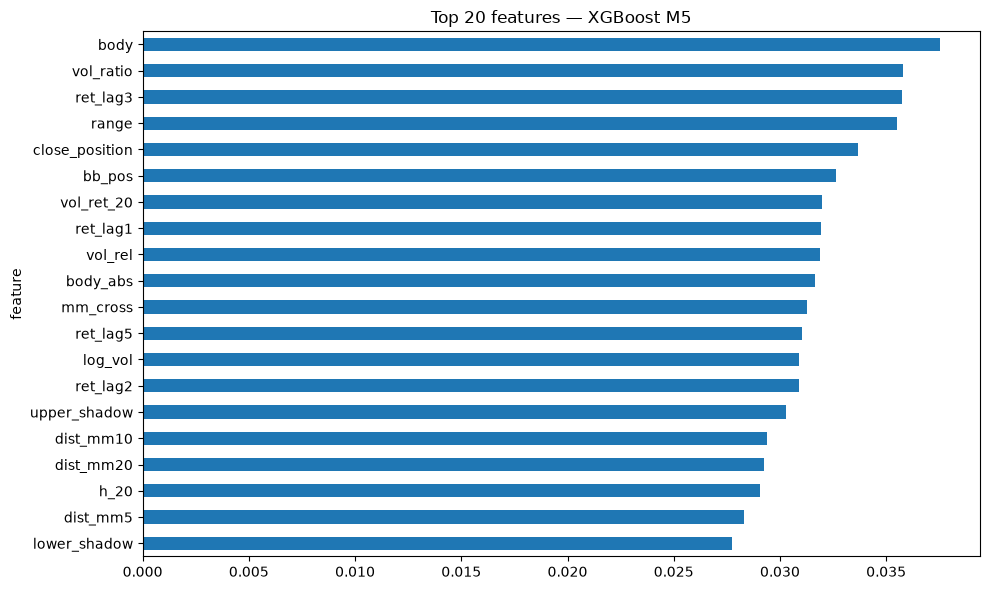

In [6]:
imp = pd.DataFrame({
    'feature': FEATURES,
    'importance': model.feature_importances_,
}).sort_values('importance', ascending=False)

print("Top 15 features:")
print(imp.head(15).to_string(index=False))

fig, ax = plt.subplots(figsize=(10, 6))
imp.head(20).sort_values('importance').plot.barh(x='feature', y='importance', ax=ax, legend=False)
ax.set_title('Top 20 features — XGBoost M5')
plt.tight_layout()
plt.show()

In [7]:
from pathlib import Path
import joblib

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
PROCESSED = ROOT / 'data' / 'processed'
PROCESSED.mkdir(exist_ok=True, parents=True)

# Dataset de features
df.to_parquet(PROCESSED / 'EURUSD_M5_features.parquet', index=False)

# Modelo treinado (não é bom, mas é referência)
joblib.dump(model, PROCESSED / 'EURUSD_M5_xgb.pkl')
joblib.dump(FEATURES, PROCESSED / 'EURUSD_M5_features_list.pkl')

# Log de resultado
import json
with open(PROCESSED / 'EURUSD_M5_resultado.json', 'w') as f:
    json.dump({
        'ativo': 'EURUSD',
        'timeframe': 'M5',
        'periodo': f"{df['time'].min()} → {df['time'].max()}",
        'n_candles': len(df),
        'n_features': len(FEATURES),
        'auc': float(auc),
        'acuracia': float(acc),
        'ic': None if np.isnan(ic) else float(ic),
        'pnl_com_custo_1pip': float(pnl_diario['pnl_acum'].iloc[-1]),
        'conclusao': 'Sem edge em M5 com 35 dias. Custo de 1 pip domina o sinal.'
    }, f, indent=2)

print("✅ Salvo em data/processed/")

✅ Salvo em data/processed/
